<a href="https://colab.research.google.com/github/EvertonSilvaz/PI_IV/blob/main/AED_PI_IV_Entrega.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Base de Dados e Links

In [1]:
import pandas as pd

In [2]:
uri = 'https://raw.githubusercontent.com/EvertonSilvaz/PI_IV/refs/heads/main/recreio_nas_ferias_dados_cadastrais_2026.csv'

In [4]:
base = pd.read_csv(uri, sep =',')

# Visão Geral do Conjunto de Dados

In [5]:
base.head()

,ID_INSCRICAO,ID_ALUNO,GENERO,IDADE,DATA,HORARIO,ATIVIDADE,DESCRICAO_ATIVIDADE
0,INS0001,ALU0001,Masculino,14,2026-01-07,09:00,Vôlei,Vôlei recreativo
1,INS0002,ALU0002,Masculino,14,2026-01-07,09:00,Vôlei,Fundamentos do vôlei
2,INS0003,ALU0003,Feminino,8,2026-01-07,09:00,Tênis de mesa,Desafios de pingue-pongue
3,INS0004,ALU0004,Masculino,12,2026-01-07,09:00,Trabalhos manuais e oficina de desenho,Trabalhos manuais
4,INS0005,ALU0005,Masculino,7,2026-01-07,09:00,Trabalhos manuais e oficina de desenho,Oficina de desenho


In [6]:
base.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14420 entries, 0 to 14419
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID_INSCRICAO         14420 non-null  object
 1   ID_ALUNO             14420 non-null  object
 2   GENERO               14420 non-null  object
 3   IDADE                14420 non-null  int64 
 4   DATA                 14420 non-null  object
 5   HORARIO              14420 non-null  object
 6   ATIVIDADE            14420 non-null  object
 7   DESCRICAO_ATIVIDADE  14420 non-null  object
dtypes: int64(1), object(7)
memory usage: 901.4+ KB


Quantas participações nas atividades existem em cada idade?

In [7]:
base["IDADE"].value_counts().sort_index(ascending=True)

,count
IDADE,
4,588
5,720
6,1024
7,1272
8,1720
9,1876
10,1908
11,1676
12,1448


In [8]:
base.columns

Index(['ID_INSCRICAO', 'ID_ALUNO', 'GENERO', 'IDADE', 'DATA', 'HORARIO',
       'ATIVIDADE', 'DESCRICAO_ATIVIDADE'],
      dtype='object')

In [9]:
#Idades distintas
base["IDADE"].nunique()

11

Quantas crianças distintas temos em cada idade?

### Tratamento e organização dos dados

Inicialmente, foi considerada a totalidade dos registros disponíveis na base de dados. Entretanto, verificou-se que um mesmo participante poderia estar associado a diferentes atividades, ocasionando múltiplas ocorrências do mesmo identificador.

Diante disso, foi realizada uma distinção entre os registros de atividades e os participantes únicos. Para as análises relacionadas às características individuais dos alunos, foi utilizada a identificação `ID_ALUNO`, permitindo eliminar registros duplicados e obter um conjunto de 300 participantes distintos.

Essa separação foi necessária para evitar que alunos associados a várias atividades tivessem peso maior nas análises individuais, garantindo que cada participante fosse contabilizado uma única vez nos cálculos de idade e gênero.

A base completa, por sua vez, foi mantida para as análises relacionadas às atividades, uma vez que um mesmo aluno pode participar de mais de uma delas.

Contando os Alunos Distintos

In [11]:
base.groupby("IDADE")["ID_ALUNO"].nunique()

,ID_ALUNO
IDADE,
4,12
5,15
6,21
7,27
8,36
9,39
10,39
11,36
12,30


In [15]:
#total de alunos
resultado.sum()

np.int64(300)

In [16]:
# Percentual: qual a participação de cada idade no total?
percentual = resultado/resultado.sum() *100
percentual.round(2) # é também a frequencia relativa

,ID_ALUNO
IDADE,
4,4.0
5,5.0
6,7.0
7,9.0
8,12.0
9,13.0
10,13.0
11,12.0
12,10.0


## Visualização gráfica

<Axes: title={'center': 'Distribuição de alunos por idade'}, xlabel='Idade (anos)', ylabel='Quantidade de alunos'>

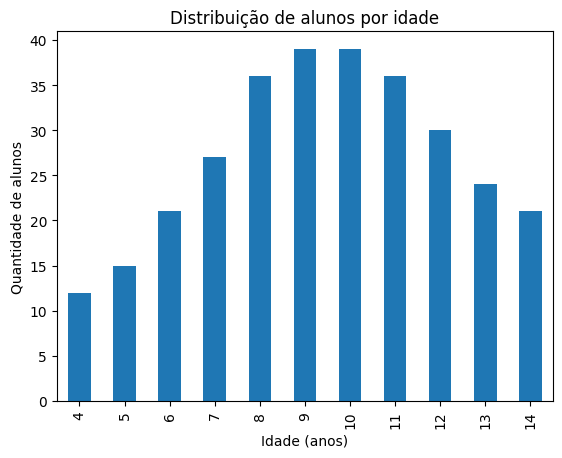

In [17]:
resultado.sort_index().plot.bar(
 xlabel = "Idade (anos)",
 ylabel = "Quantidade de alunos",
 title = "Distribuição de alunos por idade"
)

<Axes: title={'center': 'Distribuição Percentual de alunos por idade'}, xlabel='Idade (anos)', ylabel='Participação(%)'>

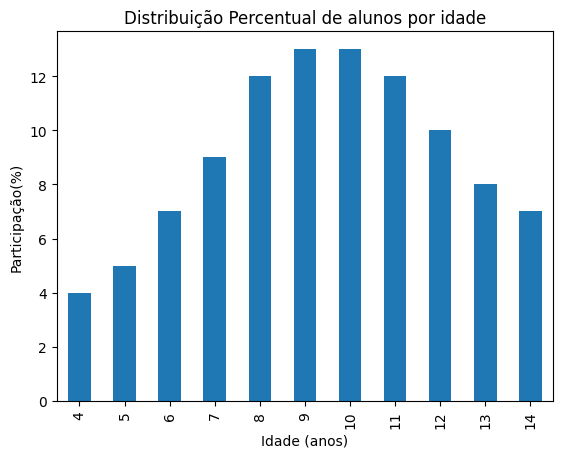

In [18]:
percentual.sort_index().plot.bar(
  xlabel="Idade (anos)" ,
  ylabel ="Participação(%)" ,
  title = "Distribuição Percentual de alunos por idade",
)

### Análise por Genero

In [19]:
base["GENERO"].value_counts()# ocorrências de generos que não são distintos

,count
GENERO,
Masculino,7408
Feminino,7012


In [20]:
genero = base.groupby("GENERO")["ID_ALUNO"].nunique()

In [21]:
percentual_genero = genero / genero.sum()*100

In [22]:
# Percentual de participantes por Gênero
percentual_genero.round(2)

,ID_ALUNO
GENERO,
Feminino,48.67
Masculino,51.33


<Axes: title={'center': 'Distribuição percentual por gênero'}, xlabel='Gênero', ylabel='Particição(%)'>

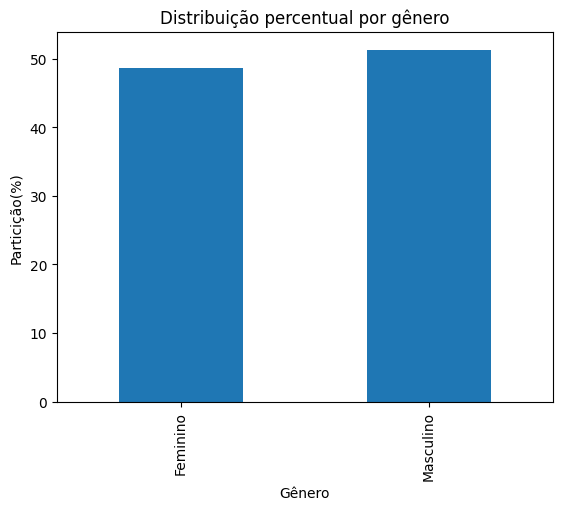

In [23]:
percentual_genero.plot.bar(
    xlabel = "Gênero",
    ylabel = "Particição(%)",
    title = "Distribuição percentual por gênero"



)

## Medidas de Tendência Central(média, mediana e moda)

Média

In [24]:
base["IDADE"].mean()

np.float64(9.432177531206657)

In [25]:
round(float(base["IDADE"].mean()), 2)


9.43

In [26]:
media = base["IDADE"].mean()

print(f"{media:.2f} anos")

9.43 anos


Mediana

In [27]:
mediana = base["IDADE"].median()
print(f"Idade mediana dos participantes: {mediana:.0f} anos")

Idade mediana dos participantes: 10 anos



Moda

In [28]:
moda = base["IDADE"].mode()
print(f"Idade mais frequente: {moda.iloc[0]} anos")

Idade mais frequente: 10 anos


# Visão dos dados por alunos Distintos


In [29]:
alunos = base.drop_duplicates(subset = "ID_ALUNO")

In [30]:
alunos

,ID_INSCRICAO,ID_ALUNO,GENERO,IDADE,DATA,HORARIO,ATIVIDADE,DESCRICAO_ATIVIDADE
0,INS0001,ALU0001,Masculino,14,2026-01-07,09:00,Vôlei,Vôlei recreativo
1,INS0002,ALU0002,Masculino,14,2026-01-07,09:00,Vôlei,Fundamentos do vôlei
2,INS0003,ALU0003,Feminino,8,2026-01-07,09:00,Tênis de mesa,Desafios de pingue-pongue
3,INS0004,ALU0004,Masculino,12,2026-01-07,09:00,Trabalhos manuais e oficina de desenho,Trabalhos manuais
4,INS0005,ALU0005,Masculino,7,2026-01-07,09:00,Trabalhos manuais e oficina de desenho,Oficina de desenho
...,...,...,...,...,...,...,...,...
295,INS0296,ALU0296,Masculino,7,2026-01-07,09:00,Trabalhos manuais e oficina de desenho,Trabalhos manuais
296,INS0297,ALU0297,Feminino,5,2026-01-07,09:00,Trabalhos manuais e oficina de desenho,Pintura e criação
297,INS0298,ALU0298,Masculino,10,2026-01-07,09:00,Trabalhos manuais e oficina de desenho,Pintura e criação
298,INS0299,ALU0299,Masculino,7,2026-01-07,09:00,Trabalhos manuais e oficina de desenho,Trabalhos manuais


In [31]:
alunos.head()


,ID_INSCRICAO,ID_ALUNO,GENERO,IDADE,DATA,HORARIO,ATIVIDADE,DESCRICAO_ATIVIDADE
0,INS0001,ALU0001,Masculino,14,2026-01-07,09:00,Vôlei,Vôlei recreativo
1,INS0002,ALU0002,Masculino,14,2026-01-07,09:00,Vôlei,Fundamentos do vôlei
2,INS0003,ALU0003,Feminino,8,2026-01-07,09:00,Tênis de mesa,Desafios de pingue-pongue
3,INS0004,ALU0004,Masculino,12,2026-01-07,09:00,Trabalhos manuais e oficina de desenho,Trabalhos manuais
4,INS0005,ALU0005,Masculino,7,2026-01-07,09:00,Trabalhos manuais e oficina de desenho,Oficina de desenho


In [32]:
alunos.tail()

,ID_INSCRICAO,ID_ALUNO,GENERO,IDADE,DATA,HORARIO,ATIVIDADE,DESCRICAO_ATIVIDADE
295,INS0296,ALU0296,Masculino,7,2026-01-07,09:00,Trabalhos manuais e oficina de desenho,Trabalhos manuais
296,INS0297,ALU0297,Feminino,5,2026-01-07,09:00,Trabalhos manuais e oficina de desenho,Pintura e criação
297,INS0298,ALU0298,Masculino,10,2026-01-07,09:00,Trabalhos manuais e oficina de desenho,Pintura e criação
298,INS0299,ALU0299,Masculino,7,2026-01-07,09:00,Trabalhos manuais e oficina de desenho,Trabalhos manuais
299,INS0300,ALU0300,Masculino,13,2026-01-07,09:00,Futebol,Jogos recreativos de futebol


In [33]:
alunos.shape

(300, 8)

In [34]:
#Verificando o numero de IDs distintos e por consequencia o número de alunos
alunos["ID_ALUNO"].nunique()

300

## Medidas de Tendência Central(média, mediana e moda)

In [35]:
# Calculando a média de idades
alunos["IDADE"].mean()

np.float64(9.43)

In [36]:
# Calculando a mediana do grupo Alunos
alunos['IDADE'].median()

9.5

In [39]:
alunos["IDADE"].mode(dropna = True)

,IDADE
0,9
1,10


Isso significa que segue uma distribuição bimodal contendo 9 e 10 anos como as idades mais frequentes.
Distribuição bimodal: 9 e 10 anos.

In [40]:
alunos["IDADE"].mode(dropna = True).iloc[0]

np.int64(9)

In [41]:
alunos["IDADE"].mode(dropna = True).iloc[1]

np.int64(10)

In [42]:
alunos['IDADE'].value_counts(normalize= True).sort_index() # parametro normalize = true retorna a frequencia relativa

,proportion
IDADE,
4,0.04
5,0.05
6,0.07
7,0.09
8,0.12
9,0.13
10,0.13
11,0.12
12,0.10


Podemos identificar quantos alunos estão concentrados entre 8 e 11 anos e comparar esse grupo com os demais participantes. Isso nos ajudará a caracterizar melhor o público do Recreio nas Férias.

In [43]:
alunos[(alunos["IDADE"]>=8)&(alunos['IDADE']<12)]["IDADE"]

,IDADE
2,8
5,10
6,10
10,11
12,8
...,...
288,10
289,10
291,11
293,9


In [44]:
alunos[(alunos["IDADE"]>=8)&(alunos['IDADE']<12)]["IDADE"].value_counts()

,count
IDADE,
10,39
9,39
8,36
11,36


In [45]:
# Quantidade de alunos com idade entre 4 e 8 anos (frequência absoluta).
alunos[(alunos["IDADE"] >= 4) & (alunos["IDADE"] < 8)]["IDADE"].count()

np.int64(75)

In [46]:
# Quantidade de alunos com idade entre 12 e 14 anos (frequência absoluta).
alunos[(alunos["IDADE"] >= 12) & (alunos["IDADE"] < 15)]["IDADE"].count()

np.int64(75)

In [47]:
# Menor idade registrada entre os participantes
alunos["IDADE"].min()


4

In [48]:
# Maior idade registrada entre os participantes
alunos["IDADE"].max()

14

In [49]:
# Amplitude Total
alunos['IDADE'].max() - alunos['IDADE'].min()

10

## Dispersão dos Dados

In [50]:
# Desvio padrão das idades dos participantes
desvio_padrao = alunos['IDADE'].std()
print(f"Desvio padrão de {desvio_padrao:.2f} anos")

Desvio padrão de 2.70 anos


In [51]:
# Variância da idades dos participantes
variancia = alunos['IDADE'].var()
print(f"Variância: {variancia:.2f}")

Variância: 7.29


In [52]:
# Coeficiente de variação das idades dos participantes
media = alunos["IDADE"].mean()

cv = (desvio_padrao / media) * 100

print(f"Coeficiente de variação: {cv:.2f}%")

Coeficiente de variação: 28.63%


## Visualização Gráfica

### Distribuição por Idade

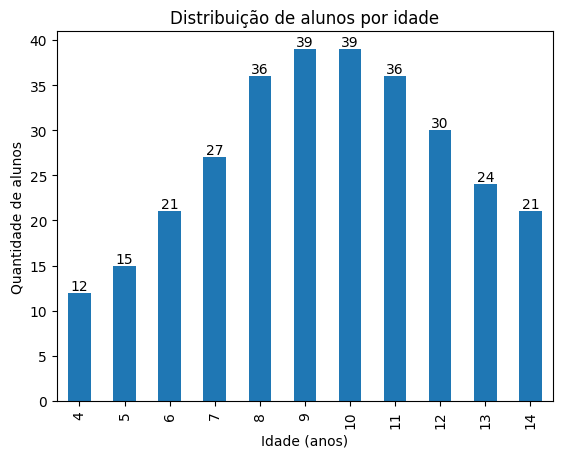

In [53]:
# Distribuição da frequência de participantes por idade
ax = resultado.sort_index().plot.bar(
    xlabel="Idade (anos)",
    ylabel="Quantidade de alunos",
    title="Distribuição de alunos por idade"
)

for barra in ax.patches:
    ax.annotate(
        str(int(barra.get_height())),
        (barra.get_x() + barra.get_width() / 2, barra.get_height()),
        ha="center",
        va="bottom"
    )

### Distribuição por Gênero

In [54]:
# Frequência absoluta
genero = alunos["GENERO"].value_counts()
genero

,count
GENERO,
Masculino,154
Feminino,146


In [55]:
# Frequência relativa (%)
genero_percentual = alunos["GENERO"].value_counts(normalize=True) * 100
genero_percentual

,proportion
GENERO,
Masculino,51.333333
Feminino,48.666667


In [56]:
# Tabela com as duas frequências
distribuicao_genero = pd.DataFrame({
    "Quantidade": genero,
    "Percentual (%)": genero_percentual
})
distribuicao_genero

,Quantidade,Percentual (%)
GENERO,,
Masculino,154,51.333333
Feminino,146,48.666667


In [57]:
distribuicao_genero["Percentual (%)"] = distribuicao_genero["Percentual (%)"].round(2)

In [58]:
distribuicao_genero

,Quantidade,Percentual (%)
GENERO,,
Masculino,154,51.33
Feminino,146,48.67


[Text(0, 0, '154'), Text(0, 0, '146')]

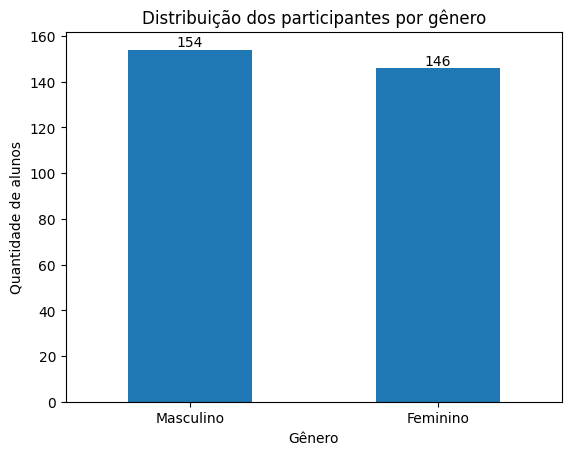

In [59]:
# Grafico de Distribuição por Gênero
ax = genero.plot.bar(
    xlabel="Gênero",
    ylabel="Quantidade de alunos",
    title="Distribuição dos participantes por gênero",
    rot=0
)

ax.bar_label(ax.containers[0])

### Distribuição por Atividades

In [60]:
# Quantidade de registros por atividade
atividade = base["ATIVIDADE"].value_counts()
atividade

,count
ATIVIDADE,
Futebol,1616
Brinquedos infláveis,1417
Piscinas e salas multiuso,1385
Cinema,1245
Dança e oficinas de dança,1206
Trabalhos manuais e oficina de desenho,1200
Teatro e apresentações culturais,1066
Queimada,1035
Brincadeiras e jogos,981


In [61]:
# Percentual de participação por atividade
atividade_percentual = base["ATIVIDADE"].value_counts(normalize=True) * 100
atividade_percentual

,proportion
ATIVIDADE,
Futebol,11.206657
Brinquedos infláveis,9.826630
Piscinas e salas multiuso,9.604716
Cinema,8.633842
Dança e oficinas de dança,8.363384
Trabalhos manuais e oficina de desenho,8.321775
Teatro e apresentações culturais,7.392510
Queimada,7.177531
Brincadeiras e jogos,6.803051


In [62]:
# Tabela de distribuição
distribuicao_atividade = pd.DataFrame({
    "Quantidade": atividade,
    "Percentual (%)": atividade_percentual.round(2)
})

distribuicao_atividade

,Quantidade,Percentual (%)
ATIVIDADE,,
Futebol,1616,11.21
Brinquedos infláveis,1417,9.83
Piscinas e salas multiuso,1385,9.60
Cinema,1245,8.63
Dança e oficinas de dança,1206,8.36
Trabalhos manuais e oficina de desenho,1200,8.32
Teatro e apresentações culturais,1066,7.39
Queimada,1035,7.18
Brincadeiras e jogos,981,6.80


[Text(3, 0, '719'),
 Text(3, 0, '752'),
 Text(3, 0, '862'),
 Text(3, 0, '936'),
 Text(3, 0, '981'),
 Text(3, 0, '1035'),
 Text(3, 0, '1066'),
 Text(3, 0, '1200'),
 Text(3, 0, '1206'),
 Text(3, 0, '1245'),
 Text(3, 0, '1385'),
 Text(3, 0, '1417'),
 Text(3, 0, '1616')]

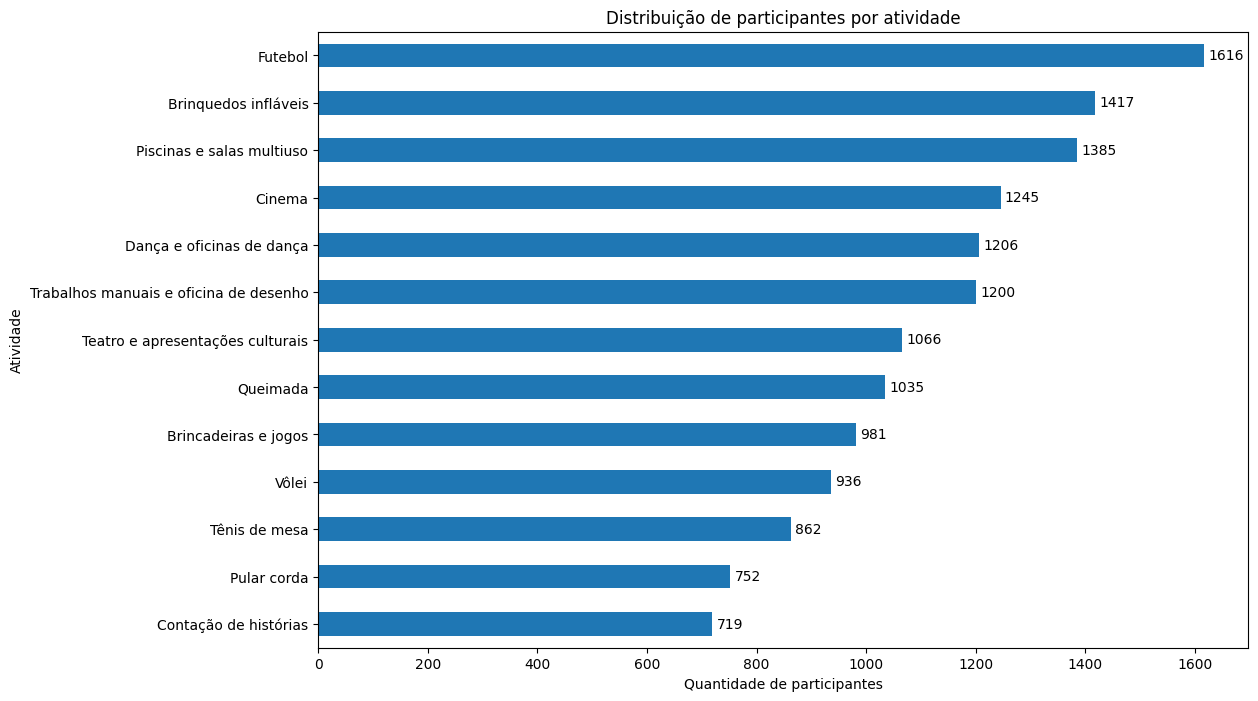

In [63]:
ax = atividade.sort_values().plot.barh(
    xlabel="Quantidade de participantes",
    ylabel="Atividade",
    title="Distribuição de participantes por atividade",
    figsize=(12, 8)
)

ax.bar_label(ax.containers[0], padding=3)

## Conclusão

A Análise Exploratória de Dados (AED) permitiu examinar as características dos participantes do programa Recreio nas Férias, utilizando recursos estatísticos para organizar, resumir e interpretar as informações.

A análise da idade revelou uma concentração de participantes entre 8 e 11 anos, faixa que representa 50% do conjunto analisado. A média foi de 9,43 anos, enquanto a mediana foi de 9,5 anos e a distribuição apresentou duas modas: 9 e 10 anos. O coeficiente de variação de 28,63% indicou a dispersão relativa das idades em torno da média.

Quanto ao gênero, observou-se uma distribuição equilibrada, com leve predominância de participantes do gênero masculino (51,33%), em comparação ao feminino (48,67%).

As análises das atividades, dos turnos, dos status das inscrições e da presença complementam a caracterização dos participantes, permitindo compreender melhor a distribuição dos registros no programa.

Conclui-se que a AED foi importante para transformar dados em informações organizadas e compreensíveis, demonstrando como medidas estatísticas, tabelas e gráficos podem auxiliar na interpretação de dados e fornecer subsídios para o planejamento e a organização de atividades.

In [65]:
!jupyter nbconvert --to html '/content/AED_GPT_PI_IV_limpando (1).ipynb'

[NbConvertApp] Converting notebook /content/AED_GPT_PI_IV_limpando (1).ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 6 image(s).
[NbConvertApp] Writing 625178 bytes to /content/AED_GPT_PI_IV_limpando (1).html
